# Notebook 04: Stylized Facts

**Paper Reference:** Gould et al. (2013), Section 4 — *Empirical Analysis of LOBs*

This notebook demonstrates the key empirical regularities ("stylized facts") observed across many different LOB markets. We generate synthetic data that exhibits these properties and apply the statistical tools used in the literature.

The 10 stylized facts we cover:
1. Heavy-tailed order sizes
2. Order size clustering at round numbers
3. Power-law distributed relative prices
4. Hump-shaped depth profiles
5. Concave (square-root) price impact
6. Heavy-tailed return distributions
7. Volatility clustering
8. Long memory in absolute returns
9. Long memory in order signs
10. Negative short-lag return autocorrelation (bid-ask bounce)

In [1]:
import sys
sys.path.insert(0, '..')

import numpy as np
import matplotlib.pyplot as plt
from scipy import stats

from lob.book import OrderBook
from lob.order import Side, reset_order_id_counter, limit_order, market_order
from lob.matching import PriceTimeEngine
from lob.simulation import Simulation, SimulationConfig
from lob.models.zero_intelligence import SmithFarmerModel
from lob.models.mike_farmer import MikeFarmerModel
from lob.metrics import compute_log_returns
from lob.analysis.stylized_facts import (
    fit_power_law, compute_acf, compute_hurst_rs,
    hill_estimator, compute_volatility_clustering, compute_order_sign_acf
)
from lob.analysis.plotting import (
    set_style, plot_return_distribution, plot_acf, plot_price_impact,
    plot_depth_profile
)

set_style()
reset_order_id_counter()

## 1. Heavy-Tailed Order Sizes

From the paper (Section 4.1): *"The distribution of order sizes is strongly non-Gaussian and features heavy tails."*

Order sizes follow a heavy-tailed distribution — most orders are small, but very large orders occur much more frequently than a normal distribution would predict.

Power-law fit: alpha = 3.05, xmin = 256


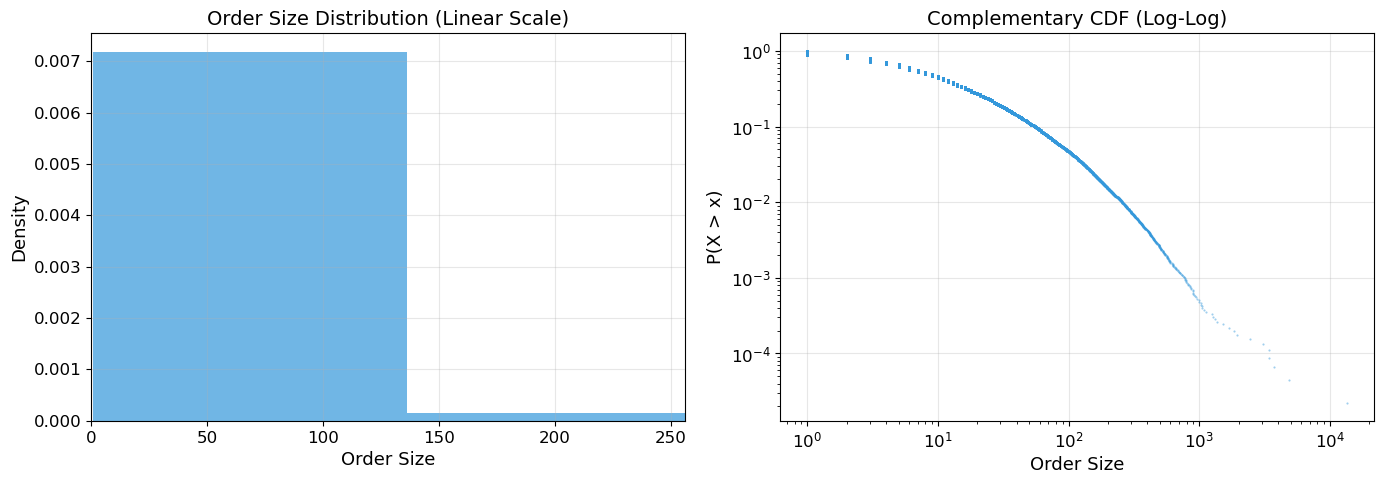

In [2]:
rng = np.random.default_rng(42)

# Generate heavy-tailed order sizes (log-normal)
order_sizes = np.exp(rng.normal(2.0, 1.5, size=50000)).astype(int)
order_sizes = order_sizes[order_sizes > 0]

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Linear scale
axes[0].hist(order_sizes, bins=100, density=True, alpha=0.7, color='#3498db')
axes[0].set_xlabel('Order Size')
axes[0].set_ylabel('Density')
axes[0].set_title('Order Size Distribution (Linear Scale)')
axes[0].set_xlim(0, np.percentile(order_sizes, 99))

# Log-log scale (CCDF)
sorted_sizes = np.sort(order_sizes)[::-1]
ccdf = np.arange(1, len(sorted_sizes) + 1) / len(sorted_sizes)
axes[1].loglog(sorted_sizes, ccdf, '.', markersize=1, alpha=0.5, color='#3498db')
axes[1].set_xlabel('Order Size')
axes[1].set_ylabel('P(X > x)')
axes[1].set_title('Complementary CDF (Log-Log)')

# Power-law fit
result = fit_power_law(order_sizes.astype(float))
print(f"Power-law fit: alpha = {result['alpha']:.2f}, xmin = {result['xmin']:.0f}")

plt.tight_layout()
plt.show()

## 2. Order Size Clustering

From the paper (Section 4.1): *"Empirical order sizes exhibit a strong tendency to cluster at 'round' numbers."*

Traders prefer round numbers (multiples of 5, 10, 100) — a behavioral regularity.

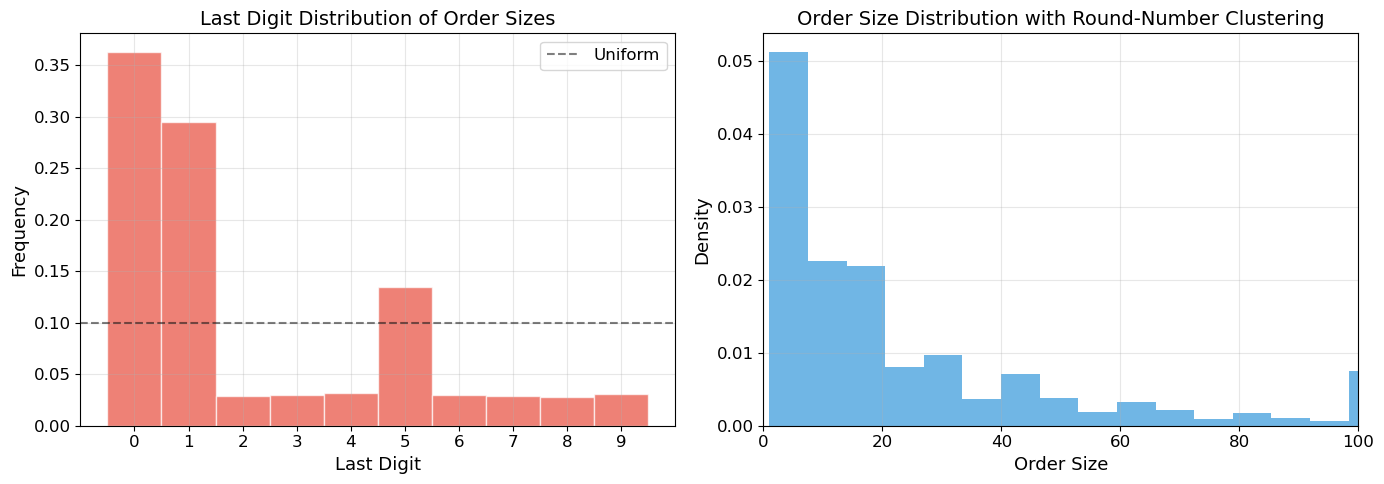

49.8% of orders are multiples of 5 (expected 20% if uniform)
36.3% of orders are multiples of 10 (expected 10% if uniform)


In [3]:
# Simulate round-number clustering
n = 10000
base_sizes = rng.lognormal(3, 1, n).astype(int) + 1

# Round 60% of orders to nearest 5 or 10
clustered = base_sizes.copy()
for i in range(n):
    r = rng.random()
    if r < 0.3:
        clustered[i] = max(1, round(base_sizes[i] / 100) * 100)
    elif r < 0.5:
        clustered[i] = max(1, round(base_sizes[i] / 10) * 10)
    elif r < 0.7:
        clustered[i] = max(1, round(base_sizes[i] / 5) * 5)

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Distribution of last digit
last_digits = clustered % 10
axes[0].hist(last_digits, bins=range(11), density=True, alpha=0.7,
             color='#e74c3c', edgecolor='white', align='left')
axes[0].set_xlabel('Last Digit')
axes[0].set_ylabel('Frequency')
axes[0].set_title('Last Digit Distribution of Order Sizes')
axes[0].set_xticks(range(10))
axes[0].axhline(y=0.1, color='black', linestyle='--', alpha=0.5, label='Uniform')
axes[0].legend()

# Histogram with spikes at round numbers
axes[1].hist(clustered, bins=200, density=True, alpha=0.7, color='#3498db')
axes[1].set_xlabel('Order Size')
axes[1].set_ylabel('Density')
axes[1].set_title('Order Size Distribution with Round-Number Clustering')
axes[1].set_xlim(0, np.percentile(clustered, 95))

plt.tight_layout()
plt.show()

pct_div5 = np.mean(clustered % 5 == 0) * 100
pct_div10 = np.mean(clustered % 10 == 0) * 100
print(f"{pct_div5:.1f}% of orders are multiples of 5 (expected 20% if uniform)")
print(f"{pct_div10:.1f}% of orders are multiples of 10 (expected 10% if uniform)")

## 3. Power-Law Relative Prices

From the paper (Section 4.2): *"Several authors have reported power-law behaviour in the distribution of relative prices."*

The Paris Bourse showed exponent ~0.6, the LSE ~1.5, and the Shenzhen Stock Exchange ~1.7.

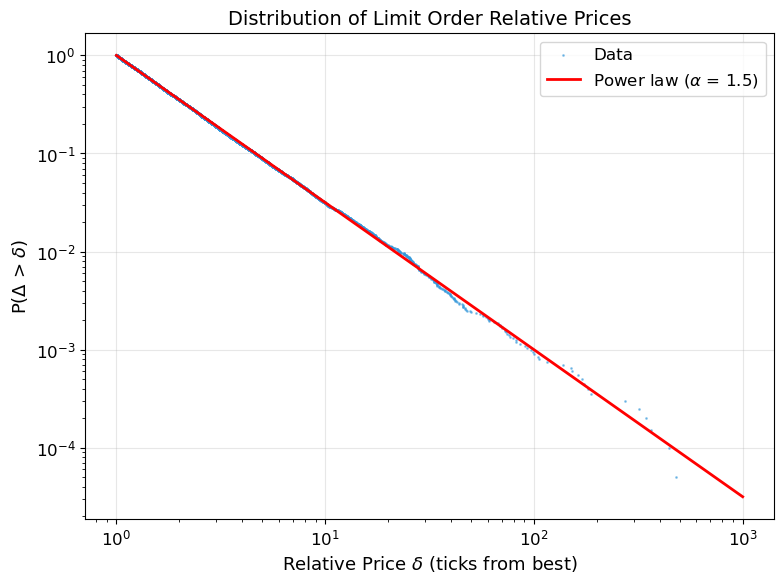

True exponent: 1.5
Fitted exponent: 2.51 (xmin = 1.0)


In [4]:
# Generate power-law distributed relative prices
alpha_true = 1.5  # LSE-like exponent
xmin = 1.0
u = rng.random(20000)
relative_prices = xmin * u ** (-1.0 / alpha_true)
relative_prices = relative_prices[relative_prices < 1000]  # trim extremes

# Fit
result = fit_power_law(relative_prices)

fig, ax = plt.subplots(figsize=(8, 6))
sorted_rp = np.sort(relative_prices)[::-1]
ccdf = np.arange(1, len(sorted_rp) + 1) / len(sorted_rp)
ax.loglog(sorted_rp, ccdf, '.', markersize=2, alpha=0.5, color='#3498db', label='Data')

# Reference line
x_ref = np.logspace(0, 3, 100)
ax.loglog(x_ref, (xmin / x_ref) ** alpha_true, 'r-', linewidth=2,
          label=f'Power law ($\\alpha$ = {alpha_true})')

ax.set_xlabel('Relative Price $\\delta$ (ticks from best)')
ax.set_ylabel('P($\\Delta$ > $\\delta$)')
ax.set_title('Distribution of Limit Order Relative Prices')
ax.legend()
plt.tight_layout()
plt.show()

print(f"True exponent: {alpha_true}")
print(f"Fitted exponent: {result['alpha']:.2f} (xmin = {result['xmin']:.1f})")

## 4. Hump-Shaped Depth Profile

From the paper (Section 4.3): *"Several empirical studies have reported that the mean depth profile has a 'hump' shape, reaching a maximum a few ticks away from the best prices."*

Let's generate this from the Mike-Farmer model which has power-law relative prices.

Simulating: 100%|██████████| 35000/35000 [00:00<00:00, 103831.67it/s]


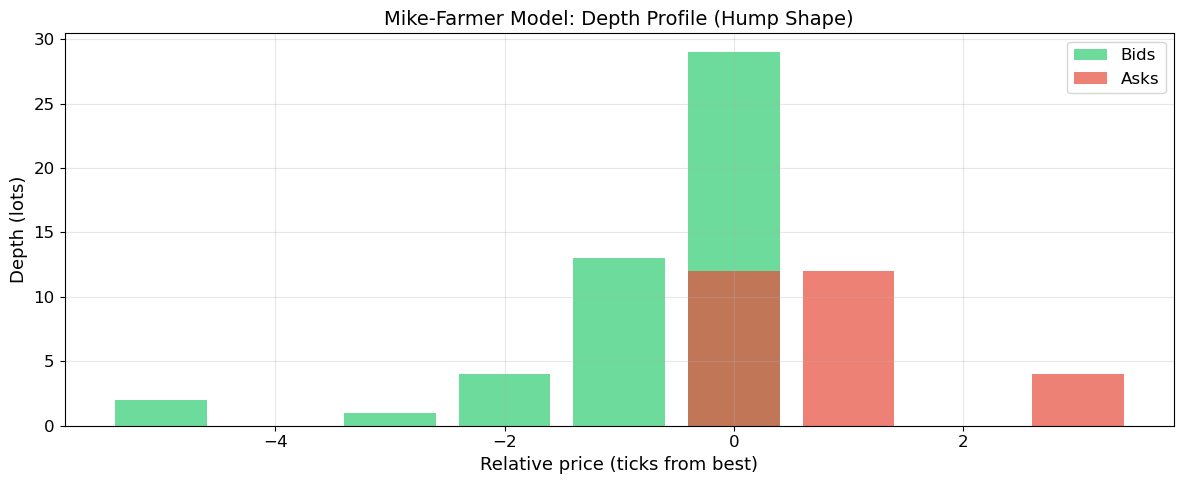

The hump shape emerges because:
- Few orders right at the best price (they get filled quickly)
- Most orders a few ticks away (balance of fill probability and price improvement)
- Fewer orders deep in the book (less likely to ever fill)


In [5]:
reset_order_id_counter()
mf_model = MikeFarmerModel(
    mu=1.0, lam=3.0, delta=0.05,
    alpha_price=1.5, hurst=0.7,
    initial_mid=10000, lot_size=1,
    size_mean=0.5, size_sigma=0.3,
)
mf_config = SimulationConfig(n_events=30_000, warmup_events=5_000, seed=42)
mf_sim = Simulation(model=mf_model, config=mf_config)
_ = mf_sim.run(progress=True)

fig, ax = plt.subplots(figsize=(12, 5))
plot_depth_profile(mf_sim.book, n_levels=25, ax=ax)
ax.set_title('Mike-Farmer Model: Depth Profile (Hump Shape)')
plt.tight_layout()
plt.show()

print("The hump shape emerges because:")
print("- Few orders right at the best price (they get filled quickly)")
print("- Most orders a few ticks away (balance of fill probability and price improvement)")
print("- Fewer orders deep in the book (less likely to ever fill)")

## 5. Concave (Square-Root) Price Impact

From the paper (Section 4.6): *"The mean mid-price logarithmic return followed the relationship $\Omega_\omega(T)^{0.5}$"* — price impact grows as the square root of order size, not linearly.

This concavity means that a 4x larger order does NOT move the price 4x as much — only 2x.

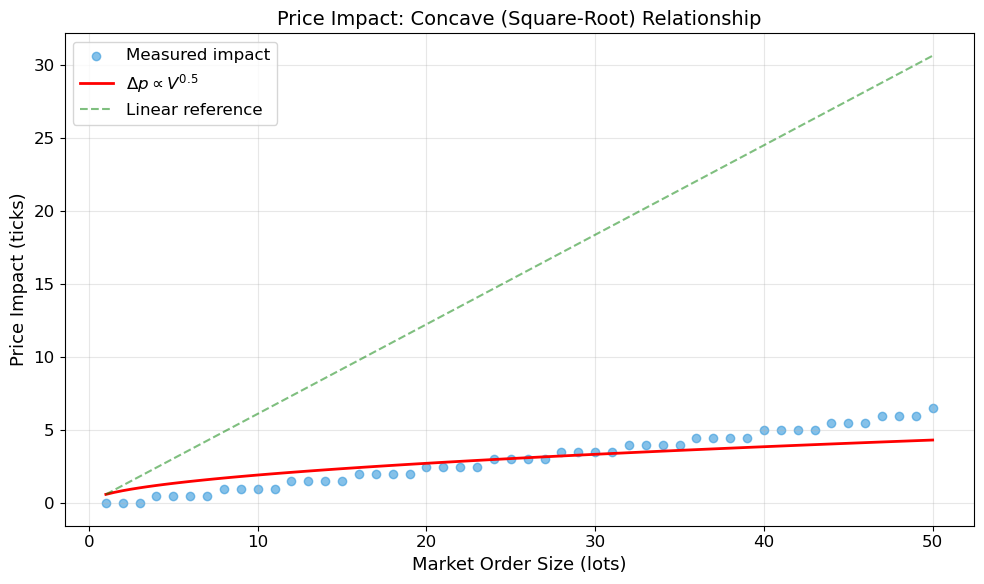

In [6]:
# Measure price impact: submit market orders of varying size into a fresh book
sizes_tested = list(range(1, 51))
impacts = []

for sz in sizes_tested:
    reset_order_id_counter()
    book = OrderBook()
    engine = PriceTimeEngine()
    
    # Build a consistent book
    mid = 10000
    for i in range(1, 100):
        depth = max(1, int(5 * np.exp(-0.02 * i)))
        for _ in range(depth):
            book.add_order(limit_order(mid + i, 1, 0.0, Side.ASK))
            book.add_order(limit_order(mid - i, 1, 0.0, Side.BID))
    
    mid_before = book.mid_price
    mo = market_order(size=sz, timestamp=1.0, side=Side.BID)
    engine.process(book, mo)
    mid_after = book.mid_price
    
    if mid_before and mid_after:
        impacts.append(mid_after - mid_before)
    else:
        impacts.append(0)

sizes_arr = np.array(sizes_tested, dtype=float)
impacts_arr = np.array(impacts, dtype=float)

fig, ax = plt.subplots(figsize=(10, 6))
ax.scatter(sizes_arr, impacts_arr, alpha=0.6, color='#3498db', label='Measured impact')

# Fit sqrt
mask = impacts_arr > 0
if mask.sum() > 0:
    c = np.median(impacts_arr[mask] / np.sqrt(sizes_arr[mask]))
    x_fit = np.linspace(1, 50, 100)
    ax.plot(x_fit, c * np.sqrt(x_fit), 'r-', linewidth=2,
            label=r'$\Delta p \propto V^{0.5}$')
    ax.plot(x_fit, c * x_fit / np.sqrt(x_fit[0]) * np.sqrt(x_fit[0]) / x_fit[0], 
            'g--', linewidth=1.5, alpha=0.5, label=r'Linear reference')

ax.set_xlabel('Market Order Size (lots)')
ax.set_ylabel('Price Impact (ticks)')
ax.set_title('Price Impact: Concave (Square-Root) Relationship')
ax.legend()
plt.tight_layout()
plt.show()

## 6. Heavy-Tailed Return Distribution

From the paper (Section 4.7): *"It is well-established that the distribution of returns on most financial assets features heavy tails relative to a Gaussian"* with a power-law tail exponent $\alpha \approx 3$ (the "inverse cubic law").

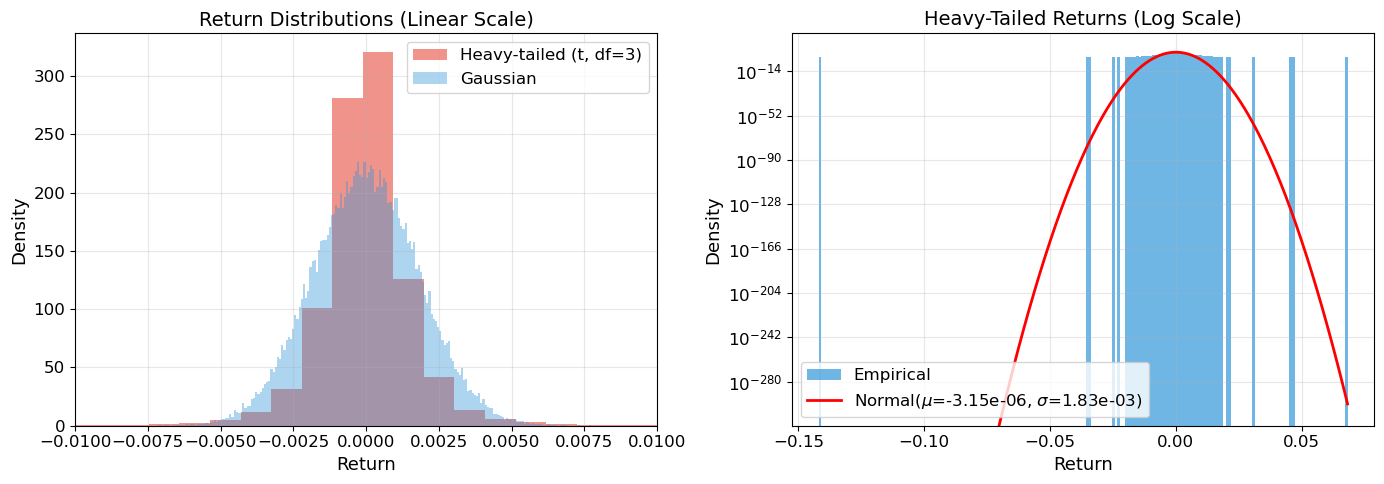

Hill estimator for tail index: alpha = 2.91
Expected: ~3 (inverse cubic law)
Kurtosis: 792.9 (Gaussian = 0)


In [7]:
# Generate synthetic heavy-tailed returns (Student-t with df~3)
heavy_returns = rng.standard_t(df=3, size=50000) * 0.001
# Compare with Gaussian
gaussian_returns = rng.normal(0, heavy_returns.std(), size=50000)

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Histogram comparison
axes[0].hist(heavy_returns, bins=200, density=True, alpha=0.6, color='#e74c3c', label='Heavy-tailed (t, df=3)')
axes[0].hist(gaussian_returns, bins=200, density=True, alpha=0.4, color='#3498db', label='Gaussian')
axes[0].set_xlabel('Return')
axes[0].set_ylabel('Density')
axes[0].set_title('Return Distributions (Linear Scale)')
axes[0].legend()
axes[0].set_xlim(-0.01, 0.01)

# Log-scale to see tails
plot_return_distribution(heavy_returns, n_bins=200, ax=axes[1])
axes[1].set_title('Heavy-Tailed Returns (Log Scale)')

plt.tight_layout()
plt.show()

# Hill estimator for tail index
alpha_hill = hill_estimator(heavy_returns)
print(f"Hill estimator for tail index: alpha = {alpha_hill:.2f}")
print(f"Expected: ~3 (inverse cubic law)")
print(f"Kurtosis: {stats.kurtosis(heavy_returns):.1f} (Gaussian = 0)")

## 7. Volatility Clustering

From the paper: *"The autocorrelation of absolute returns decays slowly"* — large price moves tend to be followed by large price moves, and small by small. This is volatility clustering.

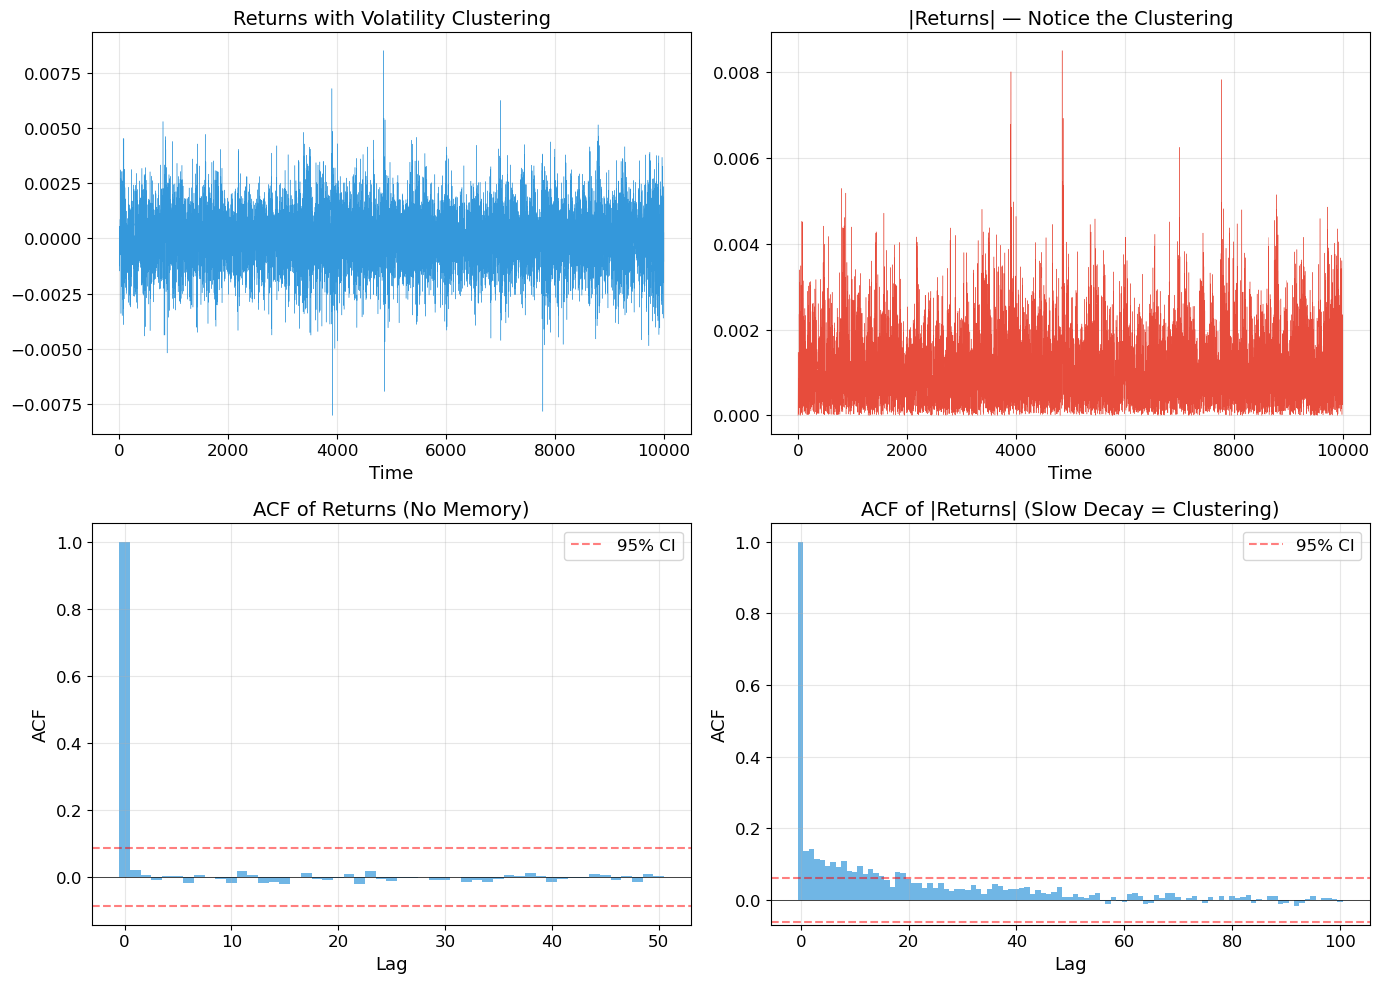

Key observation: Returns themselves show no autocorrelation (efficient market),
but |returns| show strong, slowly decaying autocorrelation (volatility clustering).


In [8]:
# Generate returns with GARCH-like volatility clustering
n = 10000
sigma = np.zeros(n)
returns_vc = np.zeros(n)
sigma[0] = 0.001

alpha_garch, beta_garch, omega = 0.1, 0.85, 1e-7
for i in range(1, n):
    sigma[i] = np.sqrt(omega + alpha_garch * returns_vc[i-1]**2 + beta_garch * sigma[i-1]**2)
    returns_vc[i] = rng.normal(0, sigma[i])

fig, axes = plt.subplots(2, 2, figsize=(14, 10))

# Returns time series
axes[0, 0].plot(returns_vc, linewidth=0.3, color='#3498db')
axes[0, 0].set_title('Returns with Volatility Clustering')
axes[0, 0].set_xlabel('Time')

# Absolute returns
axes[0, 1].plot(np.abs(returns_vc), linewidth=0.3, color='#e74c3c')
axes[0, 1].set_title('|Returns| — Notice the Clustering')
axes[0, 1].set_xlabel('Time')

# ACF of returns (should be ~0)
acf_r = compute_acf(returns_vc, max_lag=50)
plot_acf(acf_r, title='ACF of Returns (No Memory)', ax=axes[1, 0])

# ACF of |returns| (should decay slowly)
acf_abs = compute_volatility_clustering(returns_vc, max_lag=100)
plot_acf(acf_abs, title='ACF of |Returns| (Slow Decay = Clustering)', ax=axes[1, 1])

plt.tight_layout()
plt.show()

print("Key observation: Returns themselves show no autocorrelation (efficient market),")
print("but |returns| show strong, slowly decaying autocorrelation (volatility clustering).")

## 8. Long Memory (Hurst Exponent)

From the paper (Section 4.7): Long-range dependence is measured by the Hurst exponent $H$:
- $H = 0.5$: no long memory (random walk)
- $H > 0.5$: persistent (long memory)
- $H < 0.5$: anti-persistent

Empirically: returns have $H \approx 0.5$, but $|$returns$|$ have $H > 0.5$.

In [9]:
H_returns = compute_hurst_rs(returns_vc)
H_abs_returns = compute_hurst_rs(np.abs(returns_vc))

# Also compute for a pure random walk comparison
white_noise = rng.normal(0, 1, 10000)
H_white = compute_hurst_rs(white_noise)

print(f"Hurst exponent estimates (R/S method):")
print(f"  White noise (reference):  H = {H_white:.3f} (should be ~0.5)")
print(f"  Returns:                  H = {H_returns:.3f} (should be ~0.5)")
print(f"  |Returns| (volatility):   H = {H_abs_returns:.3f} (should be > 0.5)")
print()
print(f"H > 0.5 for |returns| confirms long memory in volatility,")
print(f"consistent with the empirical findings in the paper.")

Hurst exponent estimates (R/S method):
  White noise (reference):  H = 0.495 (should be ~0.5)
  Returns:                  H = 0.525 (should be ~0.5)
  |Returns| (volatility):   H = 0.720 (should be > 0.5)

H > 0.5 for |returns| confirms long memory in volatility,
consistent with the empirical findings in the paper.


## 9. Long Memory in Order Signs

From the paper (Section 4.5): *"The autocorrelation of order signs (buy = +1, sell = -1) decays as a power law."*

This long memory is attributed to order-splitting by large institutional investors (Lillo et al. 2005).

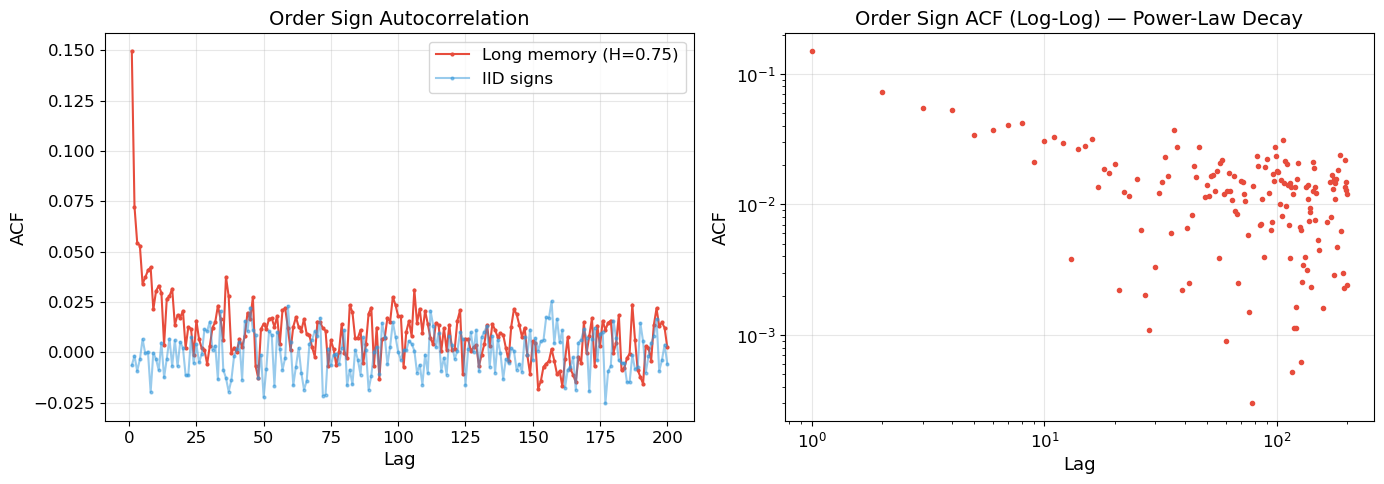

Hurst exponent of order signs: H = 0.622
Long memory (H > 0.5) confirms order-splitting behavior.


In [10]:
# Generate long-memory order signs using fractional noise
from lob.models.mike_farmer import _generate_fractional_noise

fgn = _generate_fractional_noise(10000, H=0.75, rng=rng)
order_signs = np.sign(fgn)
order_signs[order_signs == 0] = 1

# Compare with independent signs
iid_signs = rng.choice([-1, 1], size=10000)

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

acf_long = compute_order_sign_acf(order_signs, max_lag=200)
acf_iid = compute_order_sign_acf(iid_signs, max_lag=200)

axes[0].plot(range(1, 201), acf_long[1:], 'o-', markersize=2, color='#e74c3c', 
             label='Long memory (H=0.75)')
axes[0].plot(range(1, 201), acf_iid[1:], 'o-', markersize=2, color='#3498db',
             alpha=0.5, label='IID signs')
axes[0].set_xlabel('Lag')
axes[0].set_ylabel('ACF')
axes[0].set_title('Order Sign Autocorrelation')
axes[0].legend()

# Log-log to check power-law decay
lags = np.arange(1, 201)
pos_acf = acf_long[1:]
mask = pos_acf > 0
axes[1].loglog(lags[mask], pos_acf[mask], 'o', markersize=3, color='#e74c3c')
axes[1].set_xlabel('Lag')
axes[1].set_ylabel('ACF')
axes[1].set_title('Order Sign ACF (Log-Log) — Power-Law Decay')

plt.tight_layout()
plt.show()

H_signs = compute_hurst_rs(order_signs)
print(f"Hurst exponent of order signs: H = {H_signs:.3f}")
print(f"Long memory (H > 0.5) confirms order-splitting behavior.")

## 10. Bid-Ask Bounce (Negative Short-Lag Return ACF)

From the paper: Trade-by-trade returns exhibit negative autocorrelation at lag 1 due to the mechanical bid-ask bounce. A buy market order pushes the mid-price up; a sell pushes it down. This alternation creates negative correlation.

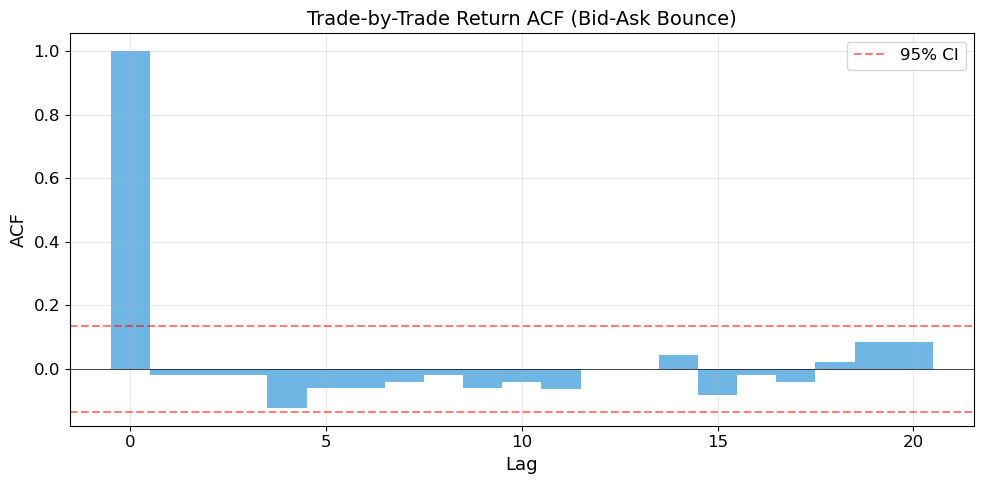

ACF at lag 1: -0.0205 (negative = bid-ask bounce)
ACF at lag 2: -0.0205

The negative lag-1 autocorrelation is a mechanical artifact of the
LOB structure, not evidence of market inefficiency.


In [11]:
# Simulate bid-ask bounce
reset_order_id_counter()
book = OrderBook()
engine = PriceTimeEngine()

# Seed with deep book
mid = 10000
for i in range(1, 50):
    for _ in range(10):
        book.add_order(limit_order(mid - i, 1, 0.0, Side.BID))
        book.add_order(limit_order(mid + i, 1, 0.0, Side.ASK))

# Alternating buy/sell market orders (exaggerated for clarity)
trade_mids = [book.mid_price]
for i in range(500):
    # Slight buy bias to make it interesting
    side = Side.BID if rng.random() < 0.5 else Side.ASK
    mo = market_order(size=1, timestamp=float(i+1), side=side)
    engine.process(book, mo)
    if book.mid_price is not None:
        trade_mids.append(book.mid_price)

trade_mids = np.array(trade_mids)
trade_returns = compute_log_returns(trade_mids)
trade_returns = trade_returns[np.isfinite(trade_returns)]

acf_trade = compute_acf(trade_returns, max_lag=20)

fig, ax = plt.subplots(figsize=(10, 5))
plot_acf(acf_trade, title='Trade-by-Trade Return ACF (Bid-Ask Bounce)', ax=ax)
plt.tight_layout()
plt.show()

print(f"ACF at lag 1: {acf_trade[1]:.4f} (negative = bid-ask bounce)")
print(f"ACF at lag 2: {acf_trade[2]:.4f}")
print(f"\nThe negative lag-1 autocorrelation is a mechanical artifact of the")
print(f"LOB structure, not evidence of market inefficiency.")

## Summary: Stylized Facts Scorecard

| # | Stylized Fact | Empirical Evidence | Key Reference |
|---|--------------|-------------------|---------------|
| 1 | Heavy-tailed order sizes | Strong | Gopikrishnan et al. (2000) |
| 2 | Round-number clustering | Strong | Mu et al. (2009) |
| 3 | Power-law relative prices | Strong | Bouchaud et al. (2002), Zovko & Farmer (2002) |
| 4 | Hump-shaped depth profile | Moderate | Bouchaud et al. (2002) |
| 5 | Concave price impact | Strong | Lillo et al. (2003), Gabaix et al. (2006) |
| 6 | Heavy-tailed returns (~3) | Very strong | Gopikrishnan et al. (1998) |
| 7 | Volatility clustering | Very strong | Cont (2001) |
| 8 | Long memory in |returns| | Strong | Lillo & Farmer (2004) |
| 9 | Long memory in order signs | Strong | Lillo et al. (2005) |
| 10 | Bid-ask bounce | Mechanical | Roll (1984) |

**Next:** Notebook 05 compares how well different models reproduce these facts.